### Data Cleaning

In [4]:
import pandas as pd

# Load the dataset
df = pd.read_csv('students.csv')

# Random sampling
sample_size = 4000
ds = df.sample(n=sample_size, replace=False, random_state=42).copy()
print("Original Dataset Shape:", df.shape)
print("Sampled Dataset Shape:", ds.shape)

# Check missing values
print("Missing Values:")
print(ds.isnull().sum())
print("Total Missing Values:", ds.isnull().sum().sum())

# Check duplicate rows and student IDs
print("Duplicate Rows:", ds.duplicated().sum())
print("Duplicate Student IDs:", ds['student_id'].duplicated().sum())

# Check parental education category
print("Parental Education - none:", (ds['parental_education'] == 'none').sum())

# Check numerical values
print("GPA Range:", ds['overall_gpa'].min(), ds['overall_gpa'].max())
print("Attendance Range:", ds['attendance_rate'].min(), ds['attendance_rate'].max())

# Check invalid values
print("Invalid GPA:", ((ds['overall_gpa'] < 0) | (ds['overall_gpa'] > 4)).sum())
print("Invalid Attendance:", ((ds['attendance_rate'] < 0) | (ds['attendance_rate'] > 100)).sum())

# Detect outliers using IQR
def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = round(float(Q1 - 1.5 * IQR), 10)
    upper_bound = round(float(Q3 + 1.5 * IQR), 10)
    return data[(data[column] < lower_bound) | (data[column] > upper_bound)]

# Check outliers
for col in ['overall_gpa', 'study_hours_per_week', 'attendance_rate']:
    print(col, "Outliers:", len(detect_outliers(ds, col)))

# Check GPA outliers in failed students
gpa_outliers = detect_outliers(ds, 'overall_gpa')
print("GPA Outliers in Failed Group:", (gpa_outliers['passed'] == 0).sum())

# Keep valid records
cleaned_dataset = ds.copy()
print("Cleaned Dataset Shape:", cleaned_dataset.shape)

Original Dataset Shape: (10000, 25)
Sampled Dataset Shape: (4000, 25)
Missing Values:
student_id                    0
age                           0
gender                        0
ethnicity                     0
parental_education            0
family_income                 0
school_type                   0
school_region                 0
study_hours_per_week          0
attendance_rate               0
extracurricular_activities    0
sports_participation          0
tutoring_sessions             0
parental_involvement          0
internet_access               0
has_laptop                    0
sleep_hours                   0
stress_level                  0
motivation_score              0
reading_score                 0
writing_score                 0
math_score                    0
science_score                 0
overall_gpa                   0
passed                        0
dtype: int64
Total Missing Values: 0
Duplicate Rows: 0
Duplicate Student IDs: 0
Parental Education - none: 214
GPA

### Treating Categorical Variables

In [5]:
import pandas as pd

# Use the cleaned sample from Data Cleaning
print("Sample Shape:", cleaned_dataset.shape)

# Select the independent variables
X = cleaned_dataset[['study_hours_per_week', 'attendance_rate',
                     'tutoring_sessions', 'sleep_hours', 'stress_level',
                     'motivation_score', 'parental_education',
                     'family_income', 'school_type',
                     'parental_involvement', 'internet_access', 'has_laptop']]

# Select the dependent variable for regression
y = cleaned_dataset['overall_gpa']

# Encode the categorical independent variables
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

# Display the results
print("Before Encoding:", X.shape)
print("After Encoding:", X_encoded.shape)
print("Missing Values After Encoding:", X_encoded.isnull().sum().sum())

print("Encoded Columns:")
print(X_encoded.columns.tolist())

print("First 5 Rows:")
print(X_encoded.head())

# Check the binary classification target
print("Classification Target Values:", cleaned_dataset['passed'].unique())

Sample Shape: (4000, 25)
Before Encoding: (4000, 12)
After Encoding: (4000, 19)
Missing Values After Encoding: 0
Encoded Columns:
['study_hours_per_week', 'attendance_rate', 'tutoring_sessions', 'sleep_hours', 'stress_level', 'motivation_score', 'parental_education_high_school', 'parental_education_master', 'parental_education_none', 'parental_education_phd', 'parental_education_some_college', 'family_income_low', 'family_income_middle', 'school_type_private', 'school_type_public', 'parental_involvement_low', 'parental_involvement_medium', 'internet_access_yes', 'has_laptop_yes']
First 5 Rows:
      study_hours_per_week  attendance_rate  tutoring_sessions  sleep_hours  \
6252                   2.4             82.4                 10          6.0   
4684                  24.3             89.3                 15          6.0   
1731                   0.0             72.5                 13          6.8   
4742                  14.7             74.2                  0          8.7   
4521

### Splitting the Dataset

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the Student Performance dataset
df = pd.read_csv('students.csv')

# Select a random sample of 4000 students
# Without replacement and with random_state=42
ds = df.sample(
    n=4000,
    replace=False,
    random_state=42
).copy()

# Select numerical independent variables
numerical_columns = [
    'study_hours_per_week',
    'attendance_rate',
    'tutoring_sessions',
    'sleep_hours',
    'stress_level',
    'motivation_score'
]

# Select categorical independent variables
categorical_columns = [
    'parental_education',
    'family_income',
    'school_type',
    'parental_involvement',
    'internet_access',
    'has_laptop'
]

# Encode categorical variables using One-Hot Encoding
# Remove one reference category from each categorical variable
X = pd.get_dummies(
    ds[numerical_columns + categorical_columns],
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Select the dependent variable
y = ds['overall_gpa']

# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display the dataset information
print("Original Dataset Shape:", df.shape)
print("Sample Dataset Shape:", ds.shape)
print("Encoded Features:", X.shape[1])

# Display the training and testing results
print("Training Set (X):", X_train.shape)
print("Testing Set (X):", X_test.shape)
print("Training Target (y):", y_train.shape)
print("Testing Target (y):", y_test.shape)

Original Dataset Shape: (10000, 25)
Sample Dataset Shape: (4000, 25)
Encoded Features: 19
Training Set (X): (3200, 19)
Testing Set (X): (800, 19)
Training Target (y): (3200,)
Testing Target (y): (800,)


### Feature Scaling

In [7]:
from sklearn.preprocessing import StandardScaler

# Create a StandardScaler object
scaler = StandardScaler()

# Make copies of the training and testing sets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit and scale the numerical training features
# Learn the mean and standard deviation from training data only
X_train_scaled[numerical_columns] = scaler.fit_transform(
    X_train[numerical_columns]
)

# Scale the testing features using the same fitted scaler
# This prevents data leakage from the testing set
X_test_scaled[numerical_columns] = scaler.transform(
    X_test[numerical_columns]
)

# Display the shape of both scaled datasets
print("Scaled Training Set:", X_train_scaled.shape)
print("Scaled Testing Set:", X_test_scaled.shape)

# Check the mean of a scaled numerical feature
print(
    "Mean of Scaled Study Hours:",
    round(
        X_train_scaled['study_hours_per_week'].mean(),
        6
    )
)

# Check the standard deviation
print(
    "Standard Deviation of Scaled Study Hours:",
    round(
        X_train_scaled['study_hours_per_week'].std(ddof=0),
        6
    )
)

# Check for missing values after feature scaling
missing_values = (
    X_train_scaled.isna().sum().sum()
    + X_test_scaled.isna().sum().sum()
)

print("Total Missing Values:", missing_values)

# Display the first five scaled training records
print("\nFirst 5 Scaled Training Records:")
print(
    X_train_scaled[numerical_columns]
    .head()
    .round(2)
)

Scaled Training Set: (3200, 19)
Scaled Testing Set: (800, 19)
Mean of Scaled Study Hours: 0.0
Standard Deviation of Scaled Study Hours: 1.0
Total Missing Values: 0

First 5 Scaled Training Records:
      study_hours_per_week  attendance_rate  tutoring_sessions  sleep_hours  \
5708                 -0.27             0.69              -1.11        -0.31   
7485                 -0.27             0.54               0.68        -0.14   
2759                 -1.34            -2.93               1.66        -0.90   
9019                  1.77             0.11              -0.46        -0.73   
6289                 -1.32             1.96               0.19         0.80   

      stress_level  motivation_score  
5708         -0.08              0.72  
7485         -0.08              0.07  
2759          0.64             -1.97  
9019          1.11              0.27  
6289         -0.81              0.32  


## Regression

### 1. Loading and Preprocessing Data

In [8]:
# Import the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Load the original dataset
original_data = pd.read_csv('students.csv')

# Select 4000 random students without replacement
sample_data = original_data.sample(
    n=4000,
    replace=False,
    random_state=42
).copy()

# Select the numerical independent variables
numerical_columns = [
    'study_hours_per_week',
    'attendance_rate',
    'tutoring_sessions',
    'sleep_hours',
    'stress_level',
    'motivation_score'
]

# Select the categorical independent variables
categorical_columns = [
    'parental_education',
    'family_income',
    'school_type',
    'parental_involvement',
    'internet_access',
    'has_laptop'
]

# Check dataset information
print("Original Dataset:", original_data.shape)
print("Sample Dataset:", sample_data.shape)

# Check for missing values
print(
    "Missing Values:",
    sample_data.isna().sum().sum()
)

# Check for duplicate records
print(
    "Duplicate Rows:",
    sample_data.duplicated().sum()
)

print(
    "Duplicate Student IDs:",
    sample_data['student_id'].duplicated().sum()
)

# Apply One-Hot Encoding to categorical variables
X = pd.get_dummies(
    sample_data[numerical_columns + categorical_columns],
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Select the dependent variable
y = sample_data['overall_gpa']

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display encoded features and split
print("Encoded Independent Variables:", X.shape)
print("Training Set Before Outlier Removal:", X_train.shape)
print("Testing Set:", X_test.shape)

# Verify that the dimensions are correct
assert sample_data.shape == (4000, 25)
assert X_train.shape == (3200, 19)
assert X_test.shape == (800, 19)

# Verify that the train and test sets do not overlap
assert len(
    X_train.index.intersection(X_test.index)
) == 0

Original Dataset: (10000, 25)
Sample Dataset: (4000, 25)
Missing Values: 0
Duplicate Rows: 0
Duplicate Student IDs: 0
Encoded Independent Variables: (4000, 19)
Training Set Before Outlier Removal: (3200, 19)
Testing Set: (800, 19)


### 2. Detecting and Removing Outliers


IQR OUTLIER DETECTION REPORT
            Variable  Lower Boundary  Upper Boundary  Number of Outliers
study_hours_per_week           -5.60           28.00                  13
     attendance_rate           60.15          106.15                   9
   tutoring_sessions          -12.50           31.50                   0
         sleep_hours            3.55           10.35                   0
        stress_level            0.15           10.15                   0
    motivation_score           -0.10           11.10                   0

Unique Outlier Records: 22
Training Records Before Removal: 3200
Training Records After Removal: 3178
Testing Records (Unchanged): 800

OUTLIERS BEFORE AND AFTER REMOVAL
                      Before Removal  After Removal (Original IQR Fences)
study_hours_per_week              13                                  0.0
attendance_rate                    9                                  0.0
tutoring_sessions                  0                              

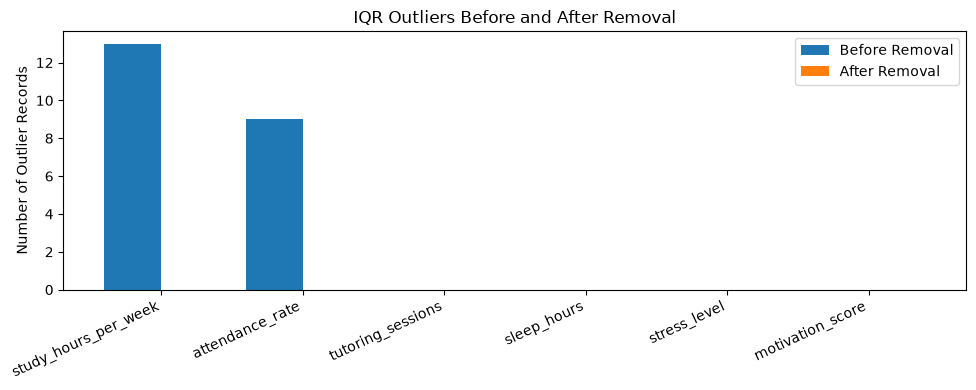

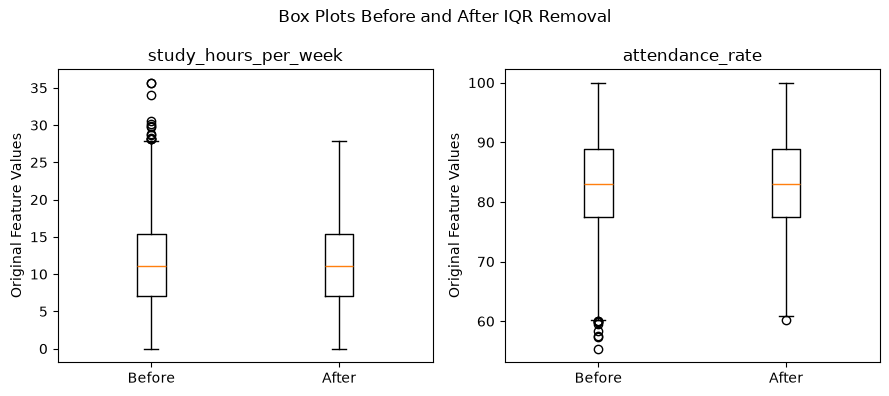

In [9]:
# Create a DataFrame to store the outlier flags
outlier_flags = pd.DataFrame(index=X_train.index)

# Store original training-set IQR boundaries
iqr_bounds = {}

# Store summary results
outlier_rows = []

# Detect outliers using the IQR method
for column in numerical_columns:

    # Calculate the first quartile
    Q1 = X_train[column].quantile(0.25)

    # Calculate the third quartile
    Q3 = X_train[column].quantile(0.75)

    # Calculate the Interquartile Range
    IQR = Q3 - Q1

    # Calculate the lower and upper boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify values outside the boundaries
    outliers = (
        (X_train[column] < lower_bound)
        | (X_train[column] > upper_bound)
    )

    # Store the boundaries
    iqr_bounds[column] = (lower_bound, upper_bound)

    # Store outlier flags
    outlier_flags[column] = outliers

    # Store the results
    outlier_rows.append({
        'Variable': column,
        'Lower Boundary': lower_bound,
        'Upper Boundary': upper_bound,
        'Number of Outliers': int(outliers.sum())
    })

# Create the outlier report
outlier_report = pd.DataFrame(outlier_rows)

print("\nIQR OUTLIER DETECTION REPORT")
print(
    outlier_report.to_string(
        index=False,
        float_format=lambda x: f'{x:.2f}'
    )
)

# Combine outliers across all numerical variables
# A record is counted once even if multiple variables flag it
any_outlier = outlier_flags.any(axis=1)

print("\nUnique Outlier Records:", int(any_outlier.sum()))

# Remove the flagged records from the training dataset
X_train_clean = X_train.loc[~any_outlier].copy()

# Keep the corresponding target values
y_train_clean = y_train.loc[X_train_clean.index].copy()

# Display before and after dataset sizes
print("Training Records Before Removal:", len(X_train))
print("Training Records After Removal:", len(X_train_clean))
print("Testing Records (Unchanged):", len(X_test))

# Verify removal
assert int(any_outlier.sum()) == 22
assert len(X_train_clean) == 3178


# Count outliers before removal
before_counts = outlier_flags.sum().astype(int)

# Count remaining observations outside the original IQR fences
after_counts = pd.Series(
    index=numerical_columns,
    dtype=int
)

for column in numerical_columns:

    lower, upper = iqr_bounds[column]

    after_counts[column] = int(
        (
            (X_train_clean[column] < lower)
            | (X_train_clean[column] > upper)
        ).sum()
    )

# Create a comparison DataFrame
outlier_comparison = pd.DataFrame({
    'Before Removal': before_counts,
    'After Removal (Original IQR Fences)': after_counts
})

print("\nOUTLIERS BEFORE AND AFTER REMOVAL")
print(outlier_comparison)

print(
    "\nTotal Remaining IQR Flags:",
    int(after_counts.sum())
)

# Verify that no records remain outside original boundaries
assert after_counts.sum() == 0

# Visualize the number of outliers before and after removal
fig, ax = plt.subplots(figsize=(10, 4))

positions = np.arange(len(numerical_columns))

ax.bar(
    positions - 0.2,
    before_counts.values,
    width=0.4,
    label='Before Removal'
)

ax.bar(
    positions + 0.2,
    after_counts.values,
    width=0.4,
    label='After Removal'
)

ax.set_xticks(positions)
ax.set_xticklabels(
    numerical_columns,
    rotation=25,
    ha='right'
)

ax.set_ylabel('Number of Outlier Records')
ax.set_title('IQR Outliers Before and After Removal')
ax.legend()

fig.tight_layout()
plt.show()

# Additional box plots for variables with detected outliers
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, column in zip(
    axes,
    ['study_hours_per_week', 'attendance_rate']
):

    ax.boxplot([
        X_train[column],
        X_train_clean[column]
    ])

    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Before', 'After'])

    ax.set_title(column)
    ax.set_ylabel('Original Feature Values')

fig.suptitle('Box Plots Before and After IQR Removal')
fig.tight_layout()
plt.show()

### 3. Splitting Data / Scaling Cleaned Training Set

In [10]:
# Create StandardScaler
scaler = StandardScaler()

# Create copies of the training and testing datasets
X_train_scaled = X_train_clean.copy()
X_test_scaled = X_test.copy()

# Fit StandardScaler only on the cleaned training records
X_train_scaled[numerical_columns] = scaler.fit_transform(
    X_train_clean[numerical_columns]
)

# Use the fitted scaler on the unchanged testing data
X_test_scaled[numerical_columns] = scaler.transform(
    X_test[numerical_columns]
)

# Display final shapes
print("\nFINAL MODELING DATASET SHAPES")
print("Clean Scaled Training Set:", X_train_scaled.shape)
print("Scaled Testing Set:", X_test_scaled.shape)
print("Training Target:", y_train_clean.shape)
print("Testing Target:", y_test.shape)

# Verify feature scaling
print(
    "Mean of Scaled Study Hours:",
    round(
        X_train_scaled['study_hours_per_week'].mean(),
        6
    )
)

print(
    "Standard Deviation of Scaled Study Hours:",
    round(
        X_train_scaled['study_hours_per_week'].std(ddof=0),
        6
    )
)


FINAL MODELING DATASET SHAPES
Clean Scaled Training Set: (3178, 19)
Scaled Testing Set: (800, 19)
Training Target: (3178,)
Testing Target: (800,)
Mean of Scaled Study Hours: -0.0
Standard Deviation of Scaled Study Hours: 1.0


### 4. Applying the Five Regression Models

In [11]:
# Create the four linear and regularized regression models
models = {
    'Multiple Linear Regression': LinearRegression(),

    'Ridge Regression': Ridge(
        alpha=0.1
    ),

    'Lasso Regression': Lasso(
        alpha=0.1,
        max_iter=20000
    ),

    'Elastic Net Regression': ElasticNet(
        alpha=0.1,
        l1_ratio=0.5,
        max_iter=20000,
        random_state=42
    )
}

# Store trained models and predictions
results = {}

# Train four models using the scaled datasets
for name, model in models.items():

    model.fit(X_train_scaled, y_train_clean)

    results[name] = {
        'model': model,
        'train_prediction': model.predict(X_train_scaled),
        'test_prediction': model.predict(X_test_scaled)
    }

# Polynomial Regression (Degree 2)
# Select the three numerical features for polynomial expansion
poly_columns = [
    'study_hours_per_week',
    'tutoring_sessions',
    'sleep_hours'
]

# Generate polynomial and interaction terms
poly_transformer = PolynomialFeatures(
    degree=2,
    include_bias=False
)

# Create polynomial training features
train_poly_terms = pd.DataFrame(
    poly_transformer.fit_transform(
        X_train_clean[poly_columns]
    ),
    columns=poly_transformer.get_feature_names_out(
        poly_columns
    ),
    index=X_train_clean.index
)

# Create polynomial testing features
test_poly_terms = pd.DataFrame(
    poly_transformer.transform(
        X_test[poly_columns]
    ),
    columns=poly_transformer.get_feature_names_out(
        poly_columns
    ),
    index=X_test.index
)

# Combine unchanged predictors with polynomial terms
X_train_poly = pd.concat(
    [
        X_train_clean.drop(columns=poly_columns),
        train_poly_terms
    ],
    axis=1
)

X_test_poly = pd.concat(
    [
        X_test.drop(columns=poly_columns),
        test_poly_terms
    ],
    axis=1
)

# Train Polynomial Regression
polynomial_model = LinearRegression()

polynomial_model.fit(
    X_train_poly,
    y_train_clean
)

# Store Polynomial Regression results
results['Polynomial Regression (Degree 2)'] = {
    'model': polynomial_model,
    'train_prediction': polynomial_model.predict(X_train_poly),
    'test_prediction': polynomial_model.predict(X_test_poly)
}

print("\nFive Regression Models Trained Successfully.")
print("Polynomial Feature Count:", X_train_poly.shape[1])


Five Regression Models Trained Successfully.
Polynomial Feature Count: 25


### 5. Evaluating Model Performance

In [12]:
# Create a list to store model evaluation metrics
comparison_rows = []

# Evaluate all five regression models
for name, item in results.items():

    predicted = item['test_prediction']

    # Calculate performance metrics
    train_r2 = r2_score(
        y_train_clean,
        item['train_prediction']
    )

    test_r2 = r2_score(y_test, predicted)

    mse = mean_squared_error(
        y_test,
        predicted
    )

    rmse = np.sqrt(mse)

    mae = mean_absolute_error(
        y_test,
        predicted
    )

    comparison_rows.append({
        'Model': name,
        'Training R2': train_r2,
        'Testing R2': test_r2,
        'Testing MSE': mse,
        'Testing RMSE': rmse,
        'Testing MAE': mae
    })

# Create the model comparison DataFrame
comparison = pd.DataFrame(comparison_rows)

# Sort models from highest to lowest testing R-squared
comparison = comparison.sort_values(
    'Testing R2',
    ascending=False
).reset_index(drop=True)

# Display evaluation results
print("\nREGRESSION MODEL COMPARISON")

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f'{x:.6f}'
    )
)

# Select the best-fitting model using the highest testing R2
best_name = comparison.loc[0, 'Model']

best_model = results[best_name]['model']
best_pred = results[best_name]['test_prediction']

print("\nBEST-FITTING MODEL:", best_name)

print(
    "BEST TEST R-SQUARED:",
    f"{comparison.loc[0, 'Testing R2']:.6f}"
)


REGRESSION MODEL COMPARISON
                           Model  Training R2  Testing R2  Testing MSE  Testing RMSE  Testing MAE
Polynomial Regression (Degree 2)     0.676542    0.679056     0.110504      0.332422     0.268992
      Multiple Linear Regression     0.627866    0.616452     0.132059      0.363399     0.288312
                Ridge Regression     0.627866    0.616448     0.132061      0.363402     0.288313
          Elastic Net Regression     0.520026    0.512831     0.167737      0.409557     0.328976
                Lasso Regression     0.435766    0.433219     0.195148      0.441756     0.355399

BEST-FITTING MODEL: Polynomial Regression (Degree 2)
BEST TEST R-SQUARED: 0.679056


### 7. Printing the Regression Equation

In [13]:
# STEP 7: PRINTING THE REGRESSION EQUATIONS
import pandas as pd

# 1. Display the intercepts of all five regression models
print("INTERCEPTS OF ALL FIVE REGRESSION MODELS")

intercept_table = pd.DataFrame({
    'Model': list(results.keys()),
    'Intercept': [
        item['model'].intercept_
        for item in results.values()
    ]
})

print(intercept_table.round(6).to_string(index=False))

# 2. Display the coefficients of the linear regression models
print("\nLINEAR REGRESSION MODEL COEFFICIENTS")

linear_models = [
    'Multiple Linear Regression',
    'Ridge Regression',
    'Lasso Regression',
    'Elastic Net Regression'
]

linear_coefficients = pd.DataFrame({
    'Feature': X_train_scaled.columns
})

for name in linear_models:
    linear_coefficients[name] = results[name]['model'].coef_

display(linear_coefficients.round(6))

# 3. Display the coefficients of the best-fitting model
print("\nBEST-FITTING REGRESSION MODEL")
print("Model:", best_name)

best_model = results[best_name]['model']

print("Intercept:", round(best_model.intercept_, 10))

polynomial_coefficients = pd.DataFrame({
    'Feature': X_train_poly.columns,
    'Coefficient': best_model.coef_
})

display(polynomial_coefficients.round(10))

# 4. Print the complete best-fitting regression equation
print("\nFINAL POLYNOMIAL REGRESSION EQUATION")

print(f"Predicted GPA = {best_model.intercept_:.10f}")

for feature, coefficient in zip(
    X_train_poly.columns,
    best_model.coef_
):
    print(f"  {coefficient:+.10f} * ({feature})")

print("\nRegression equations printed successfully.")

INTERCEPTS OF ALL FIVE REGRESSION MODELS
                           Model  Intercept
      Multiple Linear Regression   3.324838
                Ridge Regression   3.324719
                Lasso Regression   3.134780
          Elastic Net Regression   3.134780
Polynomial Regression (Degree 2)  -2.845356

LINEAR REGRESSION MODEL COEFFICIENTS


,Feature,Multiple Linear Regression,Ridge Regression,Lasso Regression,Elastic Net Regression
0,study_hours_per_week,0.334442,0.334436,0.236898,0.281110
1,attendance_rate,0.142775,0.142768,0.056303,0.091068
2,tutoring_sessions,-0.006544,-0.006546,-0.000000,-0.000000
3,sleep_hours,0.059772,0.059772,0.000000,0.021334
4,stress_level,-0.147710,-0.147702,-0.049947,-0.093690
5,motivation_score,0.101272,0.101277,0.054258,0.087423
6,parental_education_high_school,-0.163532,-0.163485,-0.000000,-0.000000
7,parental_education_master,0.044180,0.044198,0.000000,0.000000
8,parental_education_none,-0.167206,-0.167079,0.000000,-0.000000
9,parental_education_phd,0.113187,0.113141,0.000000,0.000000



BEST-FITTING REGRESSION MODEL
Model: Polynomial Regression (Degree 2)
Intercept: -2.8453556443


,Feature,Coefficient
0,attendance_rate,0.017347
1,stress_level,-0.036246
2,motivation_score,0.051122
3,parental_education_high_school,-0.162390
4,parental_education_master,0.053101
5,parental_education_none,-0.164014
6,parental_education_phd,0.107850
7,parental_education_some_college,-0.057573
8,family_income_low,-0.203075
9,family_income_middle,-0.081478



FINAL POLYNOMIAL REGRESSION EQUATION
Predicted GPA = -2.8453556443
  +0.0173465376 * (attendance_rate)
  -0.0362457662 * (stress_level)
  +0.0511219102 * (motivation_score)
  -0.1623901425 * (parental_education_high_school)
  +0.0531013652 * (parental_education_master)
  -0.1640142746 * (parental_education_none)
  +0.1078504362 * (parental_education_phd)
  -0.0575732563 * (parental_education_some_college)
  -0.2030745813 * (family_income_low)
  -0.0814784746 * (family_income_middle)
  +0.0528715859 * (school_type_private)
  -0.0619359501 * (school_type_public)
  -0.1547001086 * (parental_involvement_low)
  -0.0696359213 * (parental_involvement_medium)
  +0.0433467135 * (internet_access_yes)
  +0.0506078718 * (has_laptop_yes)
  +0.0744410074 * (study_hours_per_week)
  +0.0352501355 * (tutoring_sessions)
  +1.0498098737 * (sleep_hours)
  -0.0008348534 * (study_hours_per_week^2)
  +0.0000604485 * (study_hours_per_week tutoring_sessions)
  +0.0000054162 * (study_hours_per_week sleep_hours

### 8. Actual versus Predicted Plots


FIRST TEN TESTING RECORDS
Student ID  Actual GPA  Predicted GPA  Residual (Actual - Predicted)
  STU07072        3.05         3.2536                        -0.2036
  STU06204        2.63         2.3892                         0.2408
  STU07110        2.20         2.7109                        -0.5109
  STU00220        3.19         3.1908                        -0.0008
  STU00069        2.27         2.7976                        -0.5276
  STU05323        3.48         3.2108                         0.2692
  STU00453        3.36         3.2439                         0.1161
  STU07932        4.00         4.1723                        -0.1723
  STU01261        3.26         3.2196                         0.0404
  STU02868        3.62         3.2693                         0.3507


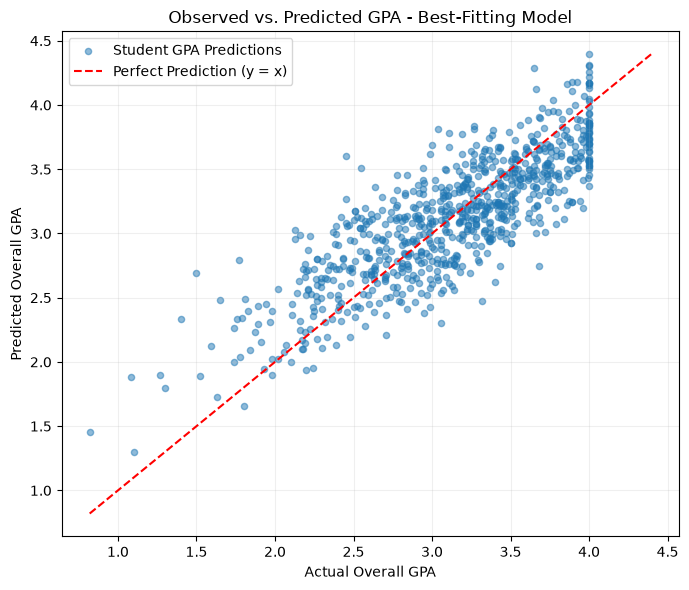

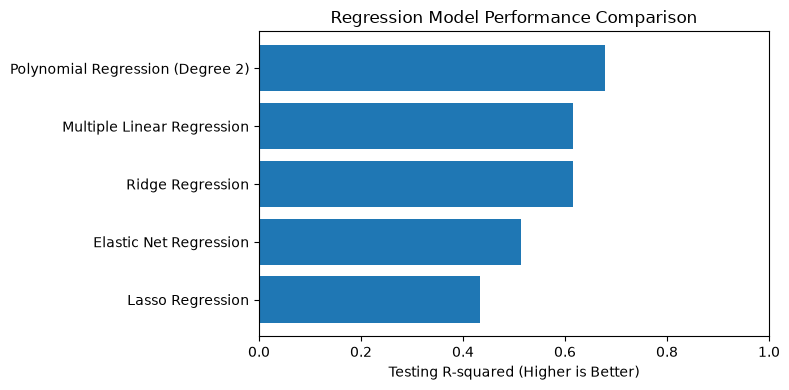


All eight regression requirements completed.


In [14]:
# Create a DataFrame comparing actual and predicted GPA
actual_vs_predicted = pd.DataFrame({
    'Student ID': sample_data.loc[
        y_test.index, 'student_id'
    ].values,

    'Actual GPA': y_test.values,

    'Predicted GPA': best_pred,

    'Residual (Actual - Predicted)':
        y_test.values - best_pred
}, index=y_test.index)

# Print the first ten testing records
print("\nFIRST TEN TESTING RECORDS")
print(
    actual_vs_predicted.head(10)
    .round(4)
    .to_string(index=False)
)

# Create actual vs predicted scatter plot
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    y_test,
    best_pred,
    alpha=0.5,
    s=20,
    label='Student GPA Predictions'
)

# Set reference-line boundaries
minimum = min(
    float(y_test.min()),
    float(np.min(best_pred))
)

maximum = max(
    float(y_test.max()),
    float(np.max(best_pred))
)

# Add red diagonal line for perfect predictions
ax.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--',
    label='Perfect Prediction (y = x)'
)

ax.set_xlabel('Actual Overall GPA')
ax.set_ylabel('Predicted Overall GPA')

ax.set_title(
    'Observed vs. Predicted GPA - Best-Fitting Model'
)

ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

# Create a chart comparing model R-squared values
fig, ax = plt.subplots(figsize=(8, 4))

ax.barh(
    comparison['Model'],
    comparison['Testing R2']
)

ax.invert_yaxis()
ax.set_xlim(0, 1)

ax.set_title('Regression Model Performance Comparison')
ax.set_xlabel('Testing R-squared (Higher is Better)')

fig.tight_layout()
plt.show()

print("\nAll eight regression requirements completed.")

### 9. Additional Regression Model — Random Forest

EXTRA MODEL: RANDOM FOREST REGRESSION
Training R2: 0.943702
Testing R2: 0.595979
Testing MSE: 0.139108
Testing RMSE: 0.372972
Testing MAE: 0.300823

COMPARISON OF ALL SIX REGRESSION MODELS
                           Model  Training R2  Testing R2  Testing MSE  Testing RMSE  Testing MAE
Polynomial Regression (Degree 2)     0.676542    0.679056     0.110504      0.332422     0.268992
      Multiple Linear Regression     0.627866    0.616452     0.132059      0.363399     0.288312
                Ridge Regression     0.627866    0.616448     0.132061      0.363402     0.288313
        Random Forest Regression     0.943702    0.595979     0.139108      0.372972     0.300823
          Elastic Net Regression     0.520026    0.512831     0.167737      0.409557     0.328976
                Lasso Regression     0.435766    0.433219     0.195148      0.441756     0.355399

BEST-FITTING MODEL AMONG SIX:
Polynomial Regression (Degree 2)


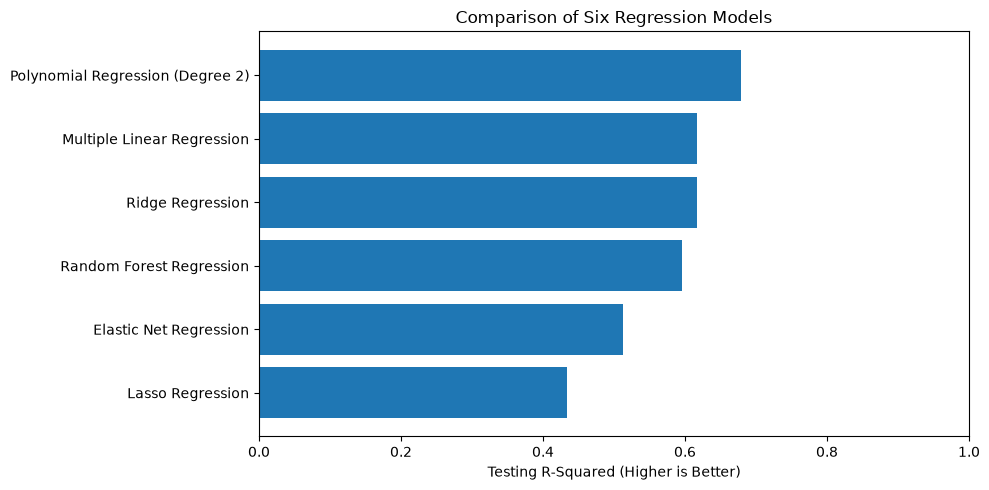


Extra regression model completed successfully.


In [15]:
# EXTRA MODEL - RANDOM FOREST REGRESSION

from sklearn.ensemble import RandomForestRegressor

# 1. Create the Random Forest Regression model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# 2. Train using the cleaned training dataset
random_forest_model.fit(X_train_clean, y_train_clean)

# 3. Predict the training and testing GPA values
rf_train_pred = random_forest_model.predict(X_train_clean)
rf_test_pred = random_forest_model.predict(X_test)

# 4. Evaluate the Random Forest model
rf_train_r2 = r2_score(y_train_clean, rf_train_pred)
rf_test_r2 = r2_score(y_test, rf_test_pred)
rf_mse = mean_squared_error(y_test, rf_test_pred)
rf_rmse = np.sqrt(rf_mse)
rf_mae = mean_absolute_error(y_test, rf_test_pred)

print("EXTRA MODEL: RANDOM FOREST REGRESSION")
print(f"Training R2: {rf_train_r2:.6f}")
print(f"Testing R2: {rf_test_r2:.6f}")
print(f"Testing MSE: {rf_mse:.6f}")
print(f"Testing RMSE: {rf_rmse:.6f}")
print(f"Testing MAE: {rf_mae:.6f}")

# 5. Add Random Forest to the existing comparison
rf_row = pd.DataFrame([{
    'Model': 'Random Forest Regression',
    'Training R2': rf_train_r2,
    'Testing R2': rf_test_r2,
    'Testing MSE': rf_mse,
    'Testing RMSE': rf_rmse,
    'Testing MAE': rf_mae
}])

comparison_all_six = pd.concat(
    [comparison, rf_row],
    ignore_index=True
)

comparison_all_six = comparison_all_six.sort_values(
    by='Testing R2',
    ascending=False
).reset_index(drop=True)

# 6. Display the updated comparison
print("\nCOMPARISON OF ALL SIX REGRESSION MODELS")
print(
    comparison_all_six.to_string(
        index=False,
        float_format=lambda x: f'{x:.6f}'
    )
)

# 7. Identify the best model among all six
best_of_six = comparison_all_six.loc[0, 'Model']

print("\nBEST-FITTING MODEL AMONG SIX:")
print(best_of_six)

# 8. Visualize the updated model comparison
plt.figure(figsize=(10, 5))

plt.barh(
    comparison_all_six['Model'],
    comparison_all_six['Testing R2']
)

plt.gca().invert_yaxis()
plt.xlim(0, 1)

plt.title('Comparison of Six Regression Models')
plt.xlabel('Testing R-Squared (Higher is Better)')

plt.tight_layout()
plt.show()

print("\nExtra regression model completed successfully.")

## Classification

### Step 1–3

In [34]:

# Step 1: Importing the Libraries
import pandas as pd
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_predict
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score,
    f1_score, classification_report
)


# Step 2: Importing the Dataset
df = pd.read_csv('students.csv')

# Select 4000 random students without replacement
ds_class = df.sample(
    n=4000,
    replace=False,
    random_state=42
).copy()


# Step 3: Selecting the Independent and Dependent Variables

# Numerical independent variables
numerical_columns = [
    'study_hours_per_week',
    'attendance_rate',
    'tutoring_sessions',
    'sleep_hours',
    'stress_level',
    'motivation_score'
]

# Categorical independent variables
categorical_columns = [
    'parental_education',
    'family_income',
    'school_type',
    'parental_involvement',
    'internet_access',
    'has_laptop'
]

# Independent variables
X = ds_class[numerical_columns + categorical_columns].copy()

# Dependent variable
y = ds_class['passed'].astype(int)

print("Independent Variables:", X.shape)
print("Dependent Variable:", y.shape)


Independent Variables: (4000, 12)
Dependent Variable: (4000,)


### Step 4–6 (one function continued across two consecutive screenshots)

In [35]:
# Step 4: Splitting the Dataset into Training and Test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Set:", X_train.shape)
print("Test Set:", X_test.shape)


# Step 5: Encoding categorical variables and Feature Scaling
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(
            drop='first',
            handle_unknown='ignore',
            sparse_output=False
        ), categorical_columns)
    ]
)


# Step 6: Defining a function to Evaluate Classification models
def Model_stat(model_name, actual, predicted):

    # Calculate the Confusion Matrix
    cm = confusion_matrix(actual, predicted, labels=[0, 1])

    # Calculate Classification errors
    errors = int(cm[0, 1] + cm[1, 0])

    # Calculate Accuracy
    accuracy = accuracy_score(actual, predicted)

    # Calculate Macro Precision
    precision = precision_score(
        actual,
        predicted,
        average='macro',
        zero_division=0
    )

    # Calculate Macro Recall
    recall = recall_score(
        actual,
        predicted,
        average='macro',
        zero_division=0
    )

    # Calculate Macro F1-Score
    f1_macro = f1_score(
        actual,
        predicted,
        average='macro',
        zero_division=0
    )

    # Calculate F1-Score for the Passed category
    f1_passed = f1_score(
        actual,
        predicted,
        pos_label=1,
        zero_division=0
    )

    # Store the evaluation results
    summary = {
        'Model': model_name,
        'Confusion Matrix': cm.tolist(),
        'Errors (FP + FN)': errors,
        'Accuracy': accuracy,
        'Precision (Macro)': precision,
        'Recall (Macro)': recall,
        'F1-Score (Macro)': f1_macro,
        'F1-Score (Passed)': f1_passed
    }

    return summary

Training Set: (3200, 12)
Test Set: (800, 12)


### Step 7–8

In [36]:

# Step 7: Defining the classification models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Support Vector Machine': SVC(),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}


# Step 8: Applying 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store classification results
results = []

for name, classifier in models.items():

    # Create the classification pipeline
    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', classifier)
    ])

    # Predict using Cross-Validation
    y_pred_cv = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv
    )

    # Evaluate and store model results
    results.append(
        Model_stat(name, y_train, y_pred_cv)
    )


### Step 9–14

In [37]:
# Step 9: Creating a DataFrame for model comparison
results_df = pd.DataFrame(results)


# Step 10: Displaying Cross-Validation Results
print("\nCross-Validation Classification Model Results:")

display(results_df[
    [
        'Model',
        'Confusion Matrix',
        'Errors (FP + FN)',
        'Accuracy'
    ]
])


# Step 11: Displaying Evaluation Metrics for All Models
print("\nEvaluation Metrics for All Models:")

display(results_df[
    [
        'Model',
        'Accuracy',
        'Precision (Macro)',
        'Recall (Macro)',
        'F1-Score (Macro)',
        'F1-Score (Passed)'
    ]
].round(4))


# Step 12: Selecting the Best-Fit classification Model
best_index = results_df['F1-Score (Macro)'].idxmax()

best_model_name = results_df.loc[best_index, 'Model']

best_cv_f1 = results_df.loc[
    best_index, 'F1-Score (Macro)'
]

print("\nBest-Fit Classification Model:")
print("Model:", best_model_name)
print("Cross-Validation Macro F1-Score:", round(best_cv_f1, 4))


# Step 13: Training the Best-Fit Model
best_classifier = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', models[best_model_name])
])

best_classifier.fit(X_train, y_train)


# Step 14: Predicting the Test Set results
y_pred = best_classifier.predict(X_test)



Cross-Validation Classification Model Results:


,Model,Confusion Matrix,Errors (FP + FN),Accuracy
0,Logistic Regression,"[[21, 101], [20, 3058]]",121,0.962187
1,K-Nearest Neighbors,"[[4, 118], [7, 3071]]",125,0.960938
2,Support Vector Machine,"[[0, 122], [0, 3078]]",122,0.961875
3,Decision Tree,"[[33, 89], [103, 2975]]",192,0.940000
4,Random Forest,"[[3, 119], [6, 3072]]",125,0.960938



Evaluation Metrics for All Models:


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Passed)
0,Logistic Regression,0.9622,0.7401,0.5828,0.6191,0.9806
1,K-Nearest Neighbors,0.9609,0.6633,0.5153,0.5201,0.9801
2,Support Vector Machine,0.9619,0.4809,0.5000,0.4903,0.9806
3,Decision Tree,0.9400,0.6068,0.6185,0.6123,0.9687
4,Random Forest,0.9609,0.6480,0.5113,0.5129,0.9801



Best-Fit Classification Model:
Model: Logistic Regression
Cross-Validation Macro F1-Score: 0.6191


### Step 15–17

In [38]:
# Step 15: Evaluating the Best-Fit Model
best_summary = Model_stat(
    best_model_name,
    y_test,
    y_pred
)

# Create a DataFrame for the best-fit model results
best_results_df = pd.DataFrame([best_summary])

print("\nBest-Fit Model Test Results:")
display(best_results_df.round(4))


# Step 16: Displaying the Number of Encoded Features
feature_count = len(
    best_classifier.named_steps[
        'preprocessor'
    ].get_feature_names_out()
)

print("\nEncoded Feature Count:", feature_count)


# Step 17: Displaying the Classification Report
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['Failed', 'Passed'],
    zero_division=0
))



Best-Fit Model Test Results:


,Model,Confusion Matrix,Errors (FP + FN),Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Passed)
0,Logistic Regression,"[[10, 21], [7, 762]]",28,0.965,0.7807,0.6567,0.6993,0.982



Encoded Feature Count: 19

Classification Report:
              precision    recall  f1-score   support

      Failed       0.59      0.32      0.42        31
      Passed       0.97      0.99      0.98       769

    accuracy                           0.96       800
   macro avg       0.78      0.66      0.70       800
weighted avg       0.96      0.96      0.96       800



### Class Counts

In [22]:
# Number of Elements Based on the Best-Fit Classifier

print("Best-Fit Classifier:", best_model_name)

# Predicted class counts
print("\nPredicted Class Counts:")
print("Number of Students Predicted to Pass:", (y_pred == 1).sum())
print("Number of Students Predicted to Fail:", (y_pred == 0).sum())

# Actual class counts in the testing dataset
print("\nActual Testing Class Counts:")
print("Number of Students Passed:", (y_test == 1).sum())
print("Number of Students Failed:", (y_test == 0).sum())

# Class counts in the original sample
print("\nOriginal Sample Class Counts:")
print("Number of Students Passed:", (y == 1).sum())
print("Number of Students Failed:", (y == 0).sum())

Best-Fit Classifier: Logistic Regression

Predicted Class Counts:
Number of Students Predicted to Pass: 783
Number of Students Predicted to Fail: 17

Actual Testing Class Counts:
Number of Students Passed: 769
Number of Students Failed: 31

Original Sample Class Counts:
Number of Students Passed: 3847
Number of Students Failed: 153


## Clustering

### Step 1–5

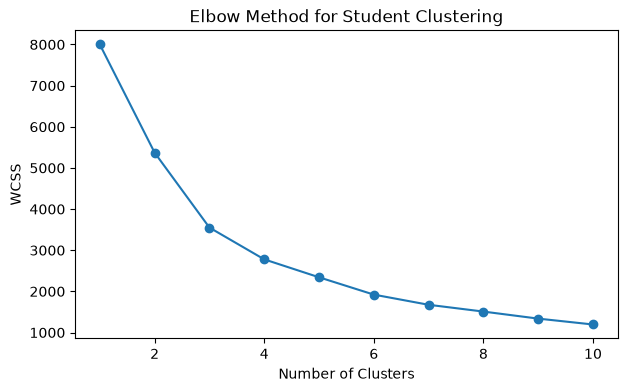

In [28]:
# Student Performance: Study Habits & GPA Dataset

# Step 1: Import the libraries for clustering and visualization
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering


# Step 2: Load the dataset and select the same 4,000-student sample used in Q2
# Random sampling without replacement ensures consistent student records.
df = pd.read_csv('students.csv')

sample_data = df.sample(
    n=4000,
    replace=False,
    random_state=42
).copy()


# Step 3: Select study hours and attendance rate as clustering features
cluster_columns = [
    'study_hours_per_week',
    'attendance_rate'
]

X_cluster = sample_data[cluster_columns].copy()


# Step 4: Standardize both features before distance-based clustering
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)


# Step 5: Use the Elbow Method to examine WCSS for K = 1 to 10
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=42
    )

    kmeans.fit(X_cluster_scaled)
    wcss.append(kmeans.inertia_)


# Visualize the Elbow Method
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title('Elbow Method for Student Clustering')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

### Step 6–7

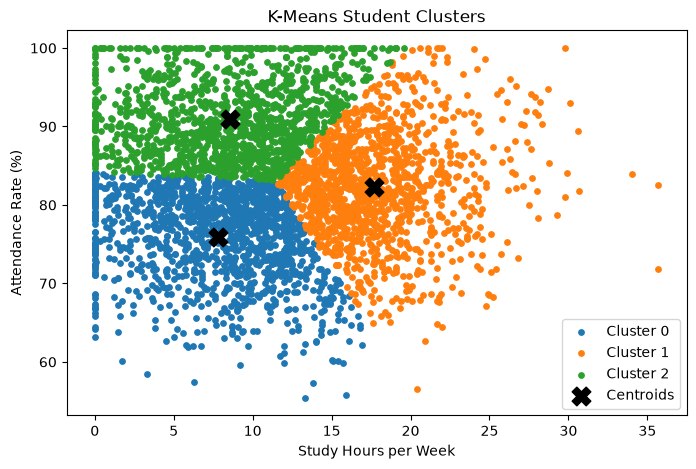


K-Means Cluster Counts:
0    1356
1    1300
2    1344
Name: count, dtype: int64


In [30]:
# Step 6: Apply K-Means to group the students into three clusters
# K = 3 was selected because the reduction in WCSS slows after three clusters.
kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    n_init=10,
    random_state=42
)

y_kmeans = kmeans.fit_predict(X_cluster_scaled)


# Calculate mean study hours and attendance for each cluster in original units
cluster_results = X_cluster.copy()
cluster_results['Cluster'] = y_kmeans

cluster_centers = cluster_results.groupby(
    'Cluster'
)[cluster_columns].mean()


# Step 7: Visualize K-Means groups and their cluster centers
plt.figure(figsize=(8, 5))

for i in range(3):
    plt.scatter(
        X_cluster.loc[
            y_kmeans == i,
            'study_hours_per_week'
        ],
        X_cluster.loc[
            y_kmeans == i,
            'attendance_rate'
        ],
        s=15,
        label='Cluster ' + str(i)
    )


# Display the cluster centers
plt.scatter(
    cluster_centers['study_hours_per_week'],
    cluster_centers['attendance_rate'],
    s=180,
    c='black',
    marker='X',
    label='Centroids'
)

plt.title('K-Means Student Clusters')
plt.xlabel('Study Hours per Week')
plt.ylabel('Attendance Rate (%)')
plt.legend()
plt.show()


# Display the number of students in each K-Means cluster
print('\nK-Means Cluster Counts:')

print(
    pd.Series(y_kmeans)
    .value_counts()
    .sort_index()
)

### Step 8

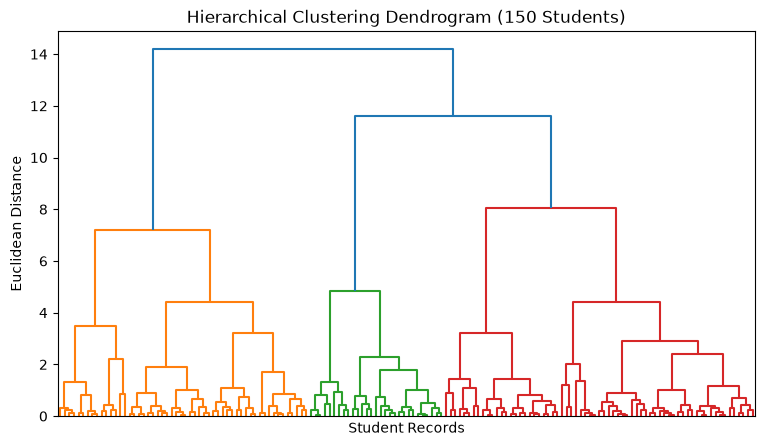

In [31]:
# Step 8: Create a Ward-linkage dendrogram to examine hierarchical structure
# Use 150 students for a readable dendrogram and apply the same fitted scaler.
X_dendrogram = X_cluster.sample(
    n=150,
    random_state=42
)

X_dendrogram_scaled = scaler_cluster.transform(
    X_dendrogram
)


# Visualize the Hierarchical Clustering dendrogram
plt.figure(figsize=(9, 5))

sch.dendrogram(
    sch.linkage(
        X_dendrogram_scaled,
        method='ward'
    ),
    no_labels=True
)

plt.title('Hierarchical Clustering Dendrogram (150 Students)')
plt.xlabel('Student Records')
plt.ylabel('Euclidean Distance')
plt.show()


### Step 9–10

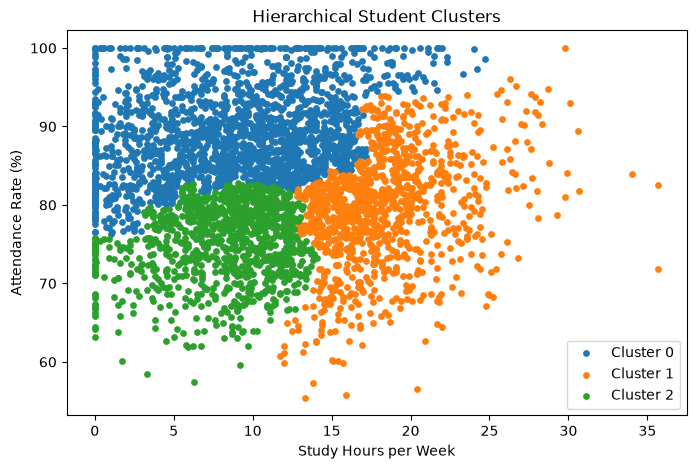


Hierarchical Cluster Counts:
0    1888
1    1072
2    1040
Name: count, dtype: int64


In [32]:
# Step 9: Apply Agglomerative Hierarchical Clustering to all 4,000 students
# Use three clusters for comparison with K-Means; the dendrogram uses a subset.
hc = AgglomerativeClustering(
    n_clusters=3,
    metric='euclidean',
    linkage='ward'
)

y_hc = hc.fit_predict(X_cluster_scaled)


# Step 10: Visualize the hierarchical clusters using the original feature values
plt.figure(figsize=(8, 5))

for i in range(3):
    plt.scatter(
        X_cluster.loc[
            y_hc == i,
            'study_hours_per_week'
        ],
        X_cluster.loc[
            y_hc == i,
            'attendance_rate'
        ],
        s=15,
        label='Cluster ' + str(i)
    )

plt.title('Hierarchical Student Clusters')
plt.xlabel('Study Hours per Week')
plt.ylabel('Attendance Rate (%)')
plt.legend()
plt.show()


# Display the number of students in each hierarchical cluster
print('\nHierarchical Cluster Counts:')

print(
    pd.Series(y_hc)
    .value_counts()
    .sort_index()
)

## Step 11

In [33]:

# Step 11 Analyze the characteristics of the K-Means clusters

clustered_data = sample_data.copy()

# Add the K-Means Cluster Labels to the dataset
clustered_data['Cluster'] = y_kmeans

# Calculate the average study hours, attendance, GPA, and pass rate
cluster_summary = clustered_data.groupby('Cluster')[
    [
        'study_hours_per_week',
        'attendance_rate',
        'overall_gpa',
        'passed'
    ]
].mean()

# Calculate the number of students in each cluster
cluster_summary['Students'] = clustered_data.groupby(
    'Cluster'
).size()

# Calculate the percentage of failed students in each cluster
# The passed variable contains 1 for passed and 0 for failed
cluster_summary['Failure Rate (%)'] = (
    1 - cluster_summary['passed']
) * 100

# Remove the pass rate from the final summary
cluster_summary = cluster_summary.drop(
    columns=['passed']
)

# Display the K-Means Cluster Summary
print("\nK-Means Cluster Summary:")
display(cluster_summary.round(2))



K-Means Cluster Summary:


,study_hours_per_week,attendance_rate,overall_gpa,Students,Failure Rate (%)
Cluster,,,,,
0,7.78,75.86,2.77,1356,9.00
1,17.68,82.24,3.47,1300,0.38
2,8.54,90.96,3.17,1344,1.93
